# Assignment 2: Data Preparation, Sampling, and Bootstrapping

**Name:** _Jochuah Kyle_
**Student ID:** _SKPNF_
**Date:** _20 Nov 2026_

Data sources (Box links from the assignment sheet):
[Q1 used cars](https://app.box.com/s/jm6pw202asu4xd3uypwtry2rqk691y1i) (downloaded as `train.csv`,
saved here as `used_cars.csv`) and
[Q2 diabetes](https://app.box.com/s/7qv44umhw0vnzgmoe9krfkfkv5kf2atv) (`diabetes.csv`).

In [1]:
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


def find_data(file_name):
    candidates = [Path("../data/data_raw") / file_name, Path(file_name),
                  Path("/content") / file_name, Path("/content/data") / file_name]
    path = next((p for p in candidates if p.is_file()), None)
    if path is None:
        raise FileNotFoundError(f"Upload {file_name} to Colab Files or put it in ../data/data_raw.")
    return path


CARS_PATH = find_data("used_cars.csv")
DIABETES_PATH = find_data("diabetes.csv")

CLEAN_DIR = Path("/content") if Path("/content").exists() else Path("../data/data_clean")
RESULTS_DIR = Path("/content") if Path("/content").exists() else Path("../data/data_results")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_COLOR = "#2a78d6"
POPULATION_COLOR = "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.25,
                     "axes.axisbelow": True, "font.size": 10})

print("Used-car data:", CARS_PATH)
print("Diabetes data:", DIABETES_PATH)
print("pandas:", pd.__version__, "numpy:", np.__version__)

Used-car data: ..\data\data_raw\used_cars.csv
Diabetes data: ..\data\data_raw\diabetes.csv
pandas: 3.0.3 numpy: 2.5.1


## Question 1 — Used car listings (20 points)

Each row is one used car listing. The target is `Price`, in lakh (1 lakh = 100,000 rupees).
The first column in the CSV has no name and is just the row number from the original file,
so I read it in as the index (`listing_id`).

| Column | Description |
|---|---|
| Name | Make and model |
| Location | City where the car is for sale |
| Year | Year of manufacture |
| Kilometers_Driven | Odometer reading, km |
| Fuel_Type | Fuel type |
| Transmission | Manual or Automatic |
| Owner_Type | Number of previous owners (First, Second, ...) |
| Mileage | Fuel efficiency, e.g. `19.67 kmpl` |
| Engine | Engine displacement, e.g. `1582 CC` |
| Power | Engine horsepower, e.g. `126.2 bhp` |
| Seats | Number of seats |
| New_Price | Price when new, e.g. `8.61 Lakh` or `1.04 Cr` |
| Price | Used price in lakh (target) |

### 1a — Missing values (4 points)

Look for the missing values in all the columns and either impute them (replace with mean, median,
or mode) or drop them. Justify your action for this task.

In [2]:
cars_raw = pd.read_csv(CARS_PATH, index_col=0)
cars_raw.index.name = "listing_id"
print("cars_raw shape:", cars_raw.shape)
display(cars_raw.head())

missing_audit = pd.DataFrame({
    "missing": cars_raw.isna().sum(),
    "missing_pct": (cars_raw.isna().mean() * 100).round(2),
    "zero_kmpl": 0,
})
missing_audit.loc["Mileage", "zero_kmpl"] = int(cars_raw["Mileage"].eq("0.0 kmpl").sum())
display(missing_audit)

engine_power_missing = cars_raw["Engine"].isna() | cars_raw["Power"].isna()
print("Rows missing Engine or Power:", int(engine_power_missing.sum()))
print("Missing both Engine and Power:", int((cars_raw["Engine"].isna() & cars_raw["Power"].isna()).sum()))
print("Also missing Seats:", int((engine_power_missing & cars_raw["Seats"].isna()).sum()))
print("Blank Mileage by Fuel_Type:",
      cars_raw.loc[cars_raw["Mileage"].isna(), "Fuel_Type"].value_counts().to_dict())
print("Fuel_Type counts:", cars_raw["Fuel_Type"].value_counts().to_dict())

cars_raw shape: (5847, 13)


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
listing_id,,,,,,,,,,,,,
1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13 km/kg,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74
6,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,3.50


,missing,missing_pct,zero_kmpl
Name,0,0.00,0
Location,0,0.00,0
Year,0,0.00,0
Kilometers_Driven,0,0.00,0
Fuel_Type,0,0.00,0
Transmission,0,0.00,0
Owner_Type,0,0.00,0
Mileage,2,0.03,40
Engine,36,0.62,0
Power,36,0.62,0


Rows missing Engine or Power: 36
Missing both Engine and Power: 36
Also missing Seats: 36
Blank Mileage by Fuel_Type: {'Electric': 2}
Fuel_Type counts: {'Diesel': 3161, 'Petrol': 2684, 'Electric': 2}


In [3]:
# Apply the decisions
clean = cars_raw.copy()
clean = clean.drop(columns="New_Price")
clean = clean.dropna(subset=["Engine", "Power", "Mileage"])

seats_missing = int(clean["Seats"].isna().sum())
seats_mode = clean["Seats"].mode()[0]
clean["Seats"] = clean["Seats"].fillna(seats_mode)

# 0.0 kmpl means not recorded
clean["Mileage"] = clean["Mileage"].replace("0.0 kmpl", np.nan)

rows_dropped = len(cars_raw) - len(clean)
print(f"Rows: {len(cars_raw)} -> {len(clean)} ({rows_dropped} dropped, {rows_dropped / len(cars_raw):.2%})")
print(f"Seats filled with the mode ({seats_mode:.0f}):", seats_missing)
print("Mileage values to fill in 1b:", int(clean["Mileage"].isna().sum()))
display(clean.isna().sum().rename("missing").to_frame().T)

assert "New_Price" not in clean.columns
assert clean.drop(columns="Mileage").notna().all().all()
assert set(clean["Fuel_Type"]) == {"Diesel", "Petrol"}

Rows: 5847 -> 5809 (38 dropped, 0.65%)
Seats filled with the mode (5): 2
Mileage values to fill in 1b: 29


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
missing,0,0,0,0,0,0,0,29,0,0,0,0


### 1a written response

I checked every column with `isna()` and also looked for hidden missing values. Only Mileage, Engine, Power, Seats, and New_Price had gaps, so I handled each one based on how much was missing and why.

New_Price is missing 5,032 of 5,847 values (86.06%), so I dropped the whole column. Imputing that much would make most of the column one made-up number, and since new prices go from a few lakh to over a crore, a single mean or median would be wrong for almost every car. Engine and Power are missing on the same 36 rows (0.62%), and those rows are also missing Seats, so I dropped them. Filling two of the most important price features with a generic median would mostly add noise, and losing 36 rows barely changes anything. The only 2 blank Mileage values are the 2 Electric cars. Km per litre doesn't apply to an electric car, so I dropped those too (the assignment also describes fuel type as petrol or diesel).

After that, only 2 rows were missing Seats. I filled them with the mode (5), since seats is a whole number and 5 is by far the most common. Mileage also had 40 "0.0 kmpl" values that `isna()` doesn't catch because they're text, but no car gets 0 km per litre, so they're really missing values like the zeros in ICP-3. 11 of them were on rows I had already dropped. The other 29 get filled with the median in 1b, because I can't calculate a median until the "kmpl" text is removed. In total 38 rows were dropped (0.65%), leaving 5,809.

### 1b — Remove the units (4 points)

Remove the units from some of the attributes and only keep the numerical values (for example
remove kmpl from "Mileage", CC from "Engine", bhp from "Power", and lakh from "New_price").

In [4]:
# Unit removal solution
def strip_unit(series, unit):
    return pd.to_numeric(series.str.replace(unit, "", regex=True).str.strip())


print("Mileage units:", cars_raw["Mileage"].str.extract(r"([a-z/]+)$")[0].value_counts().to_dict())
clean["Mileage"] = strip_unit(clean["Mileage"], r"kmpl|km/kg")
clean["Engine"] = strip_unit(clean["Engine"], "CC")
clean["Power"] = strip_unit(clean["Power"], "bhp")

# Fill the "0.0 kmpl" sentinels with the median now that Mileage is numeric.
mileage_missing = int(clean["Mileage"].isna().sum())
mileage_median = clean["Mileage"].median()
clean["Mileage"] = clean["Mileage"].fillna(mileage_median)
print(f"Mileage filled with the median ({mileage_median} kmpl):", mileage_missing)

unit_columns = ["Mileage", "Engine", "Power"]
assert all(pd.api.types.is_numeric_dtype(clean[col]) for col in unit_columns)
assert clean.notna().all().all()
assert (clean["Mileage"] > 0).all()
display(cars_raw.loc[clean.index[:5], unit_columns].join(clean[unit_columns], rsuffix="_number"))
display(clean[unit_columns].describe().round(2))

Mileage units: {'kmpl': 5842, 'km/kg': 3}
Mileage filled with the median (18.2 kmpl): 29


,Mileage,Engine,Power,Mileage_number,Engine_number,Power_number
listing_id,,,,,,
1,19.67 kmpl,1582 CC,126.2 bhp,19.67,1582,126.20
2,13 km/kg,1199 CC,88.7 bhp,13.00,1199,88.70
3,20.77 kmpl,1248 CC,88.76 bhp,20.77,1248,88.76
4,15.2 kmpl,1968 CC,140.8 bhp,15.20,1968,140.80
6,23.08 kmpl,1461 CC,63.1 bhp,23.08,1461,63.10


,Mileage,Engine,Power
count,5809.00,5809.00,5809.00
mean,18.29,1631.79,113.82
std,4.10,601.72,53.89
min,6.40,624.00,34.20
25%,15.30,1198.00,78.00
50%,18.20,1497.00,98.60
75%,21.10,1991.00,139.01
max,28.40,5998.00,560.00


In [5]:
# New_Price unit conversion (1 Cr = 100 Lakh)
new_price_parts = cars_raw["New_Price"].str.extract(r"([\d.]+)\s*(Lakh|Cr)")
new_price_lakh = pd.to_numeric(new_price_parts[0]) * new_price_parts[1].map({"Lakh": 1, "Cr": 100})
assert new_price_lakh.notna().sum() == cars_raw["New_Price"].notna().sum()

print("New_Price units:", new_price_parts[1].value_counts().to_dict())
new_price_examples = pd.DataFrame({"raw": cars_raw["New_Price"], "new_price_lakh": new_price_lakh})
display(pd.concat([new_price_examples[new_price_parts[1].eq("Lakh")].head(3),
                   new_price_examples[new_price_parts[1].eq("Cr")].head(3)]))

New_Price units: {'Lakh': 798, 'Cr': 17}


,raw,new_price_lakh
listing_id,,
2,8.61 Lakh,8.61
7,21 Lakh,21.00
10,10.65 Lakh,10.65
148,1.28 Cr,128.00
327,1.04 Cr,104.00
489,1 Cr,100.00


### 1b written response

`strip_unit` removes the unit text with a regex and converts the rest with `pd.to_numeric`, which throws an error if anything besides a number is left, so it doubles as a check. Mileage, Engine, and Power are now numeric (kmpl, CC, and bhp), and the 29 "0.0 kmpl" values from 1a were filled with the median of 18.2 kmpl. I calculated the median after turning those zeros into `NaN` so they didn't pull it down.

Three Mileage values were in km/kg (used for CNG/LPG cars) instead of kmpl. I stripped those too, but technically they aren't the same unit, which doesn't matter much with only 3 rows. New_Price was dropped in 1a, but I still showed the conversion because it has a catch: 798 values are in Lakh and 17 are in Cr (crore). One crore is 100 lakh, so just deleting the text would turn `1.28 Cr` into 1.28 instead of 128. The Cr values have to be multiplied by 100 to be on the same lakh scale as `Price`.

### 1c — One-hot encoding (4 points)

Change the categorical variables ("Fuel_Type" and "Transmission") into numerical one hot encoded value.

In [6]:
# One-hot encoding solution
clean = pd.get_dummies(clean, columns=["Fuel_Type", "Transmission"], dtype=int)
one_hot_columns = [col for col in clean.columns if col.startswith(("Fuel_Type_", "Transmission_"))]

display(cars_raw.loc[clean.index[:6], ["Fuel_Type", "Transmission"]].join(clean[one_hot_columns]))
display(clean[one_hot_columns].sum().rename("count").to_frame())

assert (clean.filter(like="Fuel_Type_").sum(axis=1) == 1).all()
assert (clean.filter(like="Transmission_").sum(axis=1) == 1).all()

,Fuel_Type,Transmission,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
listing_id,,,,,,
1,Diesel,Manual,1,0,0,1
2,Petrol,Manual,0,1,0,1
3,Diesel,Manual,1,0,0,1
4,Diesel,Automatic,1,0,1,0
6,Diesel,Manual,1,0,0,1
7,Diesel,Automatic,1,0,1,0


,count
Fuel_Type_Diesel,3153
Fuel_Type_Petrol,2656
Transmission_Automatic,1702
Transmission_Manual,4107


### 1c written response

`pd.get_dummies` replaced each column with a 0/1 column for every category (`Fuel_Type_Diesel`, `Fuel_Type_Petrol`, `Transmission_Automatic`, and `Transmission_Manual`), and every car has exactly one 1 in each group. After dropping the Electric cars there are 3,153 diesel and 2,656 petrol listings, and 1,702 automatic and 4,107 manual. One-hot encoding is better than just numbering the categories (Diesel = 1, Petrol = 2) because numbers imply an order that doesn't exist. I kept all the columns, but each pair is redundant (`Fuel_Type_Petrol` is always 1 − `Fuel_Type_Diesel`), so for a linear regression I'd use `drop_first=True` to avoid the dummy variable trap.

### 1d — New feature (4 points)

Create one more feature and add this column to the dataset (you can use mutate function in R for
this). For example, you can calculate the current age of the car by subtracting "Year" value from
the current year.

In [7]:
# Car age solution
CURRENT_YEAR = date.today().year
clean = clean.assign(Car_Age=CURRENT_YEAR - clean["Year"])

print("Current year:", CURRENT_YEAR)
display(clean[["Name", "Year", "Car_Age", "Price"]].head())
display(clean["Car_Age"].describe().round(2).to_frame().T)
print("Correlation of Car_Age with Price:", round(clean["Car_Age"].corr(clean["Price"]), 3))

clean_path = CLEAN_DIR / "a2_used_cars_clean.csv"
clean.to_csv(clean_path)
print("Clean data:", clean.shape, "saved to:", clean_path)

Current year: 2026


,Name,Year,Car_Age,Price
listing_id,,,,
1,Hyundai Creta 1.6 CRDi SX Option,2015,11,12.50
2,Honda Jazz V,2011,15,4.50
3,Maruti Ertiga VDI,2012,14,6.00
4,Audi A4 New 2.0 TDI Multitronic,2013,13,17.74
6,Nissan Micra Diesel XV,2013,13,3.50


,count,mean,std,min,25%,50%,75%,max
Car_Age,5809.0,12.53,3.17,7.0,10.0,12.0,14.0,28.0


Correlation of Car_Age with Price: -0.301
Clean data: (5809, 15) saved to: ..\data\data_clean\a2_used_cars_clean.csv


### 1d written response

`Car_Age` is the current year minus `Year`, added with `assign()`, which is pandas' version of `mutate()`. The current year was 2026 when I ran this, so ages go from 7 to 28 years with a median of 12. It has a correlation of −0.301 with `Price`, so older cars sell for less, which makes sense with depreciation. The newest car is a 2019 model, so these listings are probably from around 2019 and the ages are about 7 years higher than when the cars were listed. That shifts every car by the same amount, though, so it doesn't change the order or the correlation. The cleaned data (5,809 rows, 15 columns) is saved to `data/data_clean/a2_used_cars_clean.csv`.

### 1e — select, filter, rename, mutate, arrange, summarize (4 points)

Perform select, filter, rename, mutate, arrange and summarize with group by operations (or their
equivalent operations in python) on this dataset.

In [8]:
# Automatic cars built in 2015 or later solution
# select
selected = clean[["Name", "Location", "Year", "Kilometers_Driven", "Power",
                  "Transmission_Automatic", "Price"]]
print("select:", clean.shape, "->", selected.shape)

# filter
filtered = selected[(selected["Transmission_Automatic"] == 1) & (selected["Year"] >= 2015)]
print("filter:", selected.shape, "->", filtered.shape)

# rename
renamed = filtered.rename(columns={"Kilometers_Driven": "Km_Driven", "Power": "Power_bhp",
                                   "Price": "Price_lakh"})
print("rename:", list(renamed.columns))

# mutate
mutated = renamed.assign(
    Brand=renamed["Name"].str.split().str[0].replace({"Land": "Land Rover"}),
    Price_Band=pd.cut(renamed["Price_lakh"], bins=[0, 10, 30, np.inf],
                      labels=["budget (<10)", "mid-range (10-30)", "premium (30+)"]),
)

# arrange
arranged = mutated.sort_values(["Price_lakh", "Km_Driven"], ascending=[False, True])
display(arranged.head())

select: (5809, 15) -> (5809, 7)
filter: (5809, 7) -> (800, 7)
rename: ['Name', 'Location', 'Year', 'Km_Driven', 'Power_bhp', 'Transmission_Automatic', 'Price_lakh']


,Name,Location,Year,Km_Driven,Power_bhp,Transmission_Automatic,Price_lakh,Brand,Price_Band
listing_id,,,,,,,,,
4079,Land Rover Range Rover 3.0 Diesel LWB Vogue,Hyderabad,2017,25000,255.0,1,160.00,Land Rover,premium (30+)
5919,Jaguar F Type 5.0 V8 S,Hyderabad,2015,8000,488.1,1,100.00,Jaguar,premium (30+)
1505,Land Rover Range Rover Sport SE,Kochi,2019,26013,255.0,1,97.07,Land Rover,premium (30+)
1974,BMW 7 Series 740Li,Coimbatore,2018,28060,320.0,1,93.67,BMW,premium (30+)
1984,BMW 7 Series 740Li,Bangalore,2017,17465,320.0,1,93.00,BMW,premium (30+)


In [9]:
# Summarize with group by
brand_summary = (
    arranged.groupby("Brand")
    .agg(listings=("Price_lakh", "size"),
         mean_price_lakh=("Price_lakh", "mean"),
         median_price_lakh=("Price_lakh", "median"),
         mean_power_bhp=("Power_bhp", "mean"),
         mean_km_driven=("Km_Driven", "mean"),
         median_km_driven=("Km_Driven", "median"))
    .query("listings >= 20")
    .sort_values("mean_price_lakh", ascending=False)
    .round(2)
)
display(brand_summary)

most_km = arranged.loc[arranged["Km_Driven"].idxmax()]
print(f"Most km driven: {most_km['Km_Driven']:,} km "
      f"({most_km['Year']} {most_km['Name']}, listing {most_km.name})")

band_summary = arranged.groupby("Price_Band", observed=False)["Price_lakh"].agg(["size", "mean"]).round(2)
display(band_summary)

brand_summary_path = RESULTS_DIR / "a2_q1_brand_summary.csv"
brand_summary.to_csv(brand_summary_path)
print("Saved:", brand_summary_path)

,listings,mean_price_lakh,median_price_lakh,mean_power_bhp,mean_km_driven,median_km_driven
Brand,,,,,,
Land Rover,25,52.07,44.50,191.47,40235.44,37000.0
Jaguar,21,46.75,38.00,226.95,23571.76,19000.0
Mercedes-Benz,136,38.27,35.48,189.54,32776.99,29219.0
BMW,90,38.15,33.70,212.69,108348.32,31000.0
Audi,86,34.22,30.78,197.11,43232.00,43413.5
Ford,31,23.53,29.20,168.72,34125.03,28843.0
Toyota,60,21.15,19.75,164.95,46325.68,40337.0
Skoda,38,13.60,13.85,138.42,42891.87,40000.0
Hyundai,73,10.55,9.69,115.63,34230.79,32000.0


Most km driven: 6,500,000 km (2017 BMW X5 xDrive 30d M Sport, listing 2328)


,size,mean
Price_Band,,
budget (<10),229,6.72
mid-range (10-30),304,20.40
premium (30+),267,45.44


Saved: ..\data\data_results\a2_q1_brand_summary.csv


### 1e written response

Each step feeds into the next one. I selected 7 of the 15 columns and filtered to automatic cars from 2015 or later (800 listings). Then I renamed columns to put the units back in the names (`Power_bhp`, `Price_lakh`) and used mutate to add `Brand` (the first word of `Name`, with "Land" changed to "Land Rover") and `Price_Band` (budget under 10 lakh, mid-range 10–30, premium 30+). Arranging by price puts a 2017 Land Rover Range Rover at the top at 160 lakh. The group by summary shows Land Rover (52.07 lakh) and Jaguar (46.75) as the most expensive brands and Maruti (6.07) as the cheapest, and Mercedes-Benz has the most listings (136). The price bands are pretty balanced, with 229 budget, 304 mid-range, and 267 premium cars.

The summary also shows why it's worth looking at the median. BMW's mean km driven is 108,348, but the median is only 31,000, because one 2017 BMW X5 (listing 2328) has 6,500,000 km, which is almost definitely a typo. I left it in since outliers weren't part of this task, but it would need to be fixed before building a model.

## Question 2 — Sampling and bootstrapping (20 points)

The data file diabetes.csv contains data of 768 patients. There are 8 attributes (Pregnancies,
Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, and Age) and
1 response variable, Outcome (1 = diabetes, 0 = no diabetes). For this assignment the data is
treated as the population.

Some zeros in Glucose, BloodPressure, and BMI are really missing values (like in ICP-3), but since
this file is the population I left the values as they are.

In [10]:
population = pd.read_csv(DIABETES_PATH)
print("population shape:", population.shape)
display(population.head())

population shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 2a — Random sample of 25 (5 points)

Set a seed (to ensure work reproducibility) and take a random sample of 25 observations and find
the mean Glucose and highest Glucose values of this sample and compare these statistics with the
population statistics of the same variable. You should use charts for this comparison.

,Sample (n=25),Population (N=768),Difference
Mean glucose,127.52,120.89,6.63
Highest glucose,181.00,199.00,-18.00


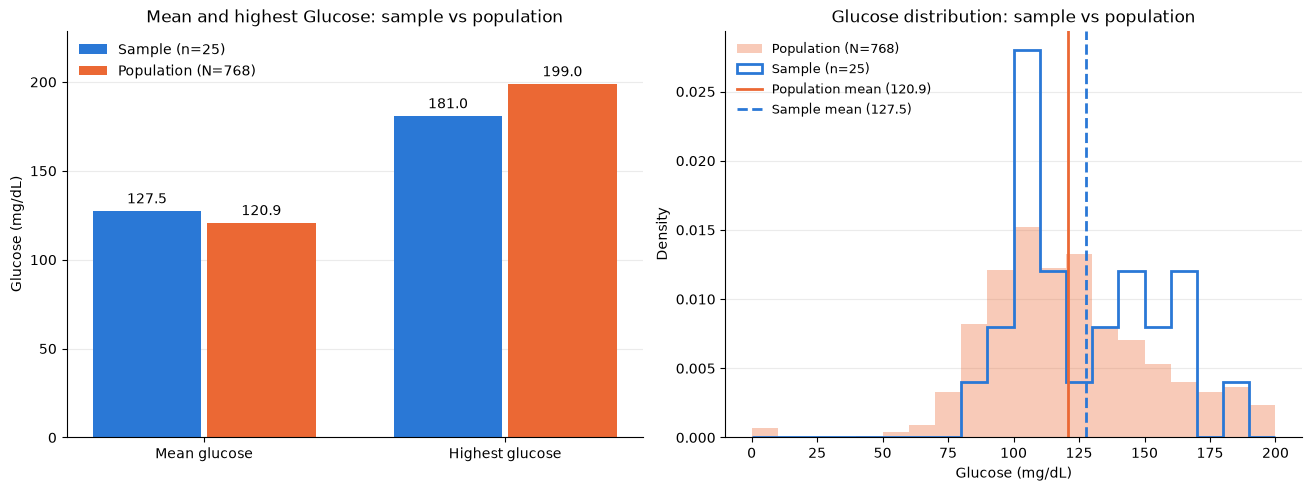

In [11]:
# Glucose comparison: sample vs population
SEED = 17
sample_25 = population.sample(n=25, random_state=SEED)

SAMPLE_LABEL, POPULATION_LABEL = "Sample (n=25)", "Population (N=768)"
glucose_comparison = pd.DataFrame({
    SAMPLE_LABEL: [sample_25["Glucose"].mean(), sample_25["Glucose"].max()],
    POPULATION_LABEL: [population["Glucose"].mean(), population["Glucose"].max()],
}, index=["Mean glucose", "Highest glucose"])
glucose_comparison["Difference"] = glucose_comparison[SAMPLE_LABEL] - glucose_comparison[POPULATION_LABEL]
display(glucose_comparison.round(2))

fig_2a, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

x = np.arange(len(glucose_comparison))
for offset, label, color in [(-0.19, SAMPLE_LABEL, SAMPLE_COLOR), (0.19, POPULATION_LABEL, POPULATION_COLOR)]:
    bars = axes[0].bar(x + offset, glucose_comparison[label], 0.36, color=color, label=label)
    axes[0].bar_label(bars, fmt="%.1f", padding=3)
axes[0].set(xticks=x, xticklabels=glucose_comparison.index, ylabel="Glucose (mg/dL)",
            ylim=(0, glucose_comparison[[SAMPLE_LABEL, POPULATION_LABEL]].to_numpy().max() * 1.15),
            title="Mean and highest Glucose: sample vs population")
axes[0].legend(frameon=False, loc="upper left")

bins = np.arange(0, 210, 10)
axes[1].hist(population["Glucose"], bins=bins, density=True, color=POPULATION_COLOR, alpha=0.35,
             label=POPULATION_LABEL)
axes[1].hist(sample_25["Glucose"], bins=bins, density=True, histtype="step", linewidth=2,
             color=SAMPLE_COLOR, label=SAMPLE_LABEL)
axes[1].axvline(population["Glucose"].mean(), color=POPULATION_COLOR, linewidth=2,
                label=f"Population mean ({population['Glucose'].mean():.1f})")
axes[1].axvline(sample_25["Glucose"].mean(), color=SAMPLE_COLOR, linewidth=2, linestyle="--",
                label=f"Sample mean ({sample_25['Glucose'].mean():.1f})")
axes[1].set(xlabel="Glucose (mg/dL)", ylabel="Density",
            title="Glucose distribution: sample vs population")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)

fig_2a_path = Path("a2_q2a_glucose.png")
fig_2a.savefig(fig_2a_path, dpi=150, bbox_inches="tight")
plt.show()

### 2a written response

With `SEED = 17`, the sample's mean Glucose is 127.52 vs 120.89 for the population, which is 6.63 higher (about 5.5%). The sample's highest Glucose is 181, 18 below the population max of 199. The means are fairly close because a mean uses every value, so the highs and lows balance out. The histogram shows this sample happened to get more values in the 140–170 range than the population, which pulled its mean up. The max works differently. A sample can never have a higher max than the population, and with 25 out of 768 there's only about a 3% chance of picking any particular patient, so the sample max will almost always come in low. A different seed would give different numbers, which is why the seed is set.

### 2b — 98th percentile of BMI (5 points)

Find the 98th percentile of BMI of your sample and the population and compare the results using charts.

,BMI 98th percentile
Sample (n=25),47.58
Population (N=768),47.53


Difference: 0.05
Two highest BMIs in the sample: [46.8, 48.3]
Population rows above the population 98th percentile: 16 of 768


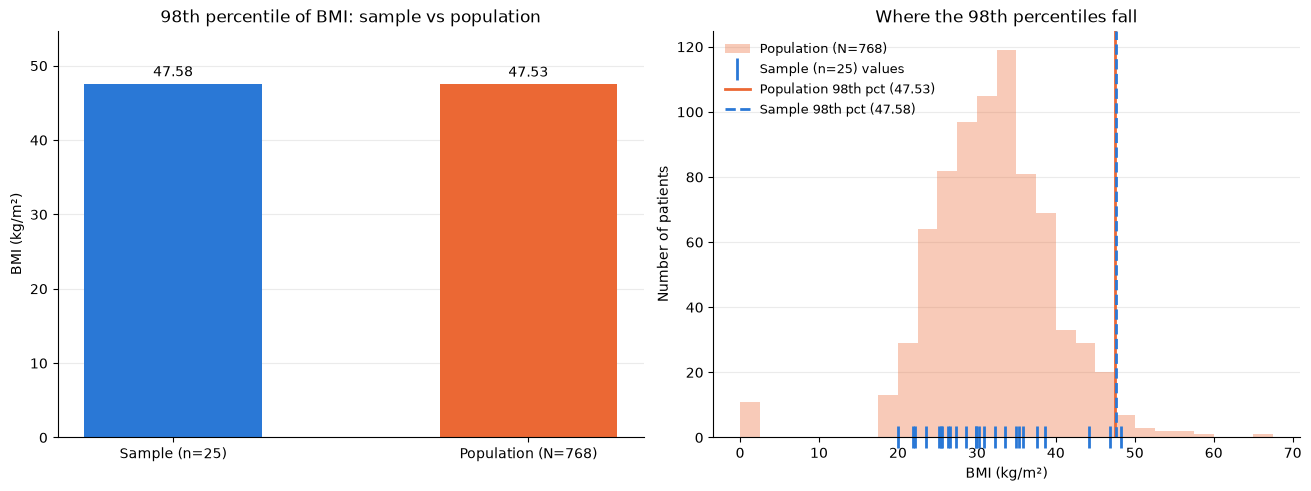

Saved: ..\data\data_results\a2_q2_sample_vs_population.csv


In [12]:
# BMI comparison: sample vs population
bmi_p98 = pd.Series({
    SAMPLE_LABEL: np.percentile(sample_25["BMI"], 98),
    POPULATION_LABEL: np.percentile(population["BMI"], 98),
}, name="BMI 98th percentile")
display(bmi_p98.round(2).to_frame())
print("Difference:", round(bmi_p98[SAMPLE_LABEL] - bmi_p98[POPULATION_LABEL], 2))
print("Two highest BMIs in the sample:", sorted(sample_25["BMI"].nlargest(2).tolist()))
print("Population rows above the population 98th percentile:",
      int((population["BMI"] > bmi_p98[POPULATION_LABEL]).sum()), "of", len(population))

fig_2b, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)

bars = axes[0].bar(bmi_p98.index, bmi_p98, width=0.5, color=[SAMPLE_COLOR, POPULATION_COLOR])
axes[0].bar_label(bars, fmt="%.2f", padding=3)
axes[0].set(ylabel="BMI (kg/m²)", ylim=(0, bmi_p98.max() * 1.15),
            title="98th percentile of BMI: sample vs population")

axes[1].hist(population["BMI"], bins=np.arange(0, 70, 2.5), color=POPULATION_COLOR, alpha=0.35,
             label=POPULATION_LABEL)
axes[1].plot(sample_25["BMI"], np.zeros(len(sample_25)), "|", color=SAMPLE_COLOR, markersize=16,
             markeredgewidth=2, clip_on=False, label=f"{SAMPLE_LABEL} values")
axes[1].axvline(bmi_p98[POPULATION_LABEL], color=POPULATION_COLOR, linewidth=2,
                label=f"Population 98th pct ({bmi_p98[POPULATION_LABEL]:.2f})")
axes[1].axvline(bmi_p98[SAMPLE_LABEL], color=SAMPLE_COLOR, linewidth=2, linestyle="--",
                label=f"Sample 98th pct ({bmi_p98[SAMPLE_LABEL]:.2f})")
axes[1].set(xlabel="BMI (kg/m²)", ylabel="Number of patients", title="Where the 98th percentiles fall")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)

fig_2b_path = Path("a2_q2b_bmi_p98.png")
fig_2b.savefig(fig_2b_path, dpi=150, bbox_inches="tight")
plt.show()

# Save the comparisons together.
sample_vs_population = pd.DataFrame({
    "statistic": ["Glucose mean", "Glucose max", "BMI 98th percentile"],
    "sample_n25": [glucose_comparison.loc["Mean glucose", SAMPLE_LABEL],
                   glucose_comparison.loc["Highest glucose", SAMPLE_LABEL], bmi_p98[SAMPLE_LABEL]],
    "population_n768": [glucose_comparison.loc["Mean glucose", POPULATION_LABEL],
                        glucose_comparison.loc["Highest glucose", POPULATION_LABEL], bmi_p98[POPULATION_LABEL]],
})
sample_vs_population["difference"] = sample_vs_population["sample_n25"] - sample_vs_population["population_n768"]
sample_vs_population_path = RESULTS_DIR / "a2_q2_sample_vs_population.csv"
sample_vs_population.to_csv(sample_vs_population_path, index=False)
print("Saved:", sample_vs_population_path)

### 2b written response

The 98th percentile of BMI is 47.58 for the sample and 47.53 for the population, only 0.05 apart, and that's mostly luck. With only 25 values the 98th percentile falls between the two highest values, so it's basically the sample's max. This sample happened to include two high BMIs (46.8 and 48.3) near the top of the population, which you can see as the tick marks on the right chart. In the population the 98th percentile is based on a lot more data, with 16 of the 768 patients above it. A different seed could easily move the sample value by several points, since extreme percentiles from small samples depend on just one or two values.

### 2c — Bootstrap (10 points)

Using bootstrap (replace = True), create 500 samples (of 150 observations each) from the population
and find the average mean, standard deviation and percentile for BloodPressure and compare this with
these statistics from the population for the same variable. Again, you should create charts for this
comparison. Report on your findings.

I used the 98th percentile, same as 2b. The population SD uses `ddof=0` since it's all 768 rows,
and each bootstrap sample's SD uses `ddof=1`.

,sample_id,mean,std,p98
0,1,69.780000,20.622159,106.00
1,2,68.340000,21.373894,98.08
2,3,68.166667,18.782191,94.00
3,4,66.653333,21.852153,98.00
4,5,69.453333,19.704388,100.04


,population,bootstrap_average,bootstrap_spread_sd,bootstrap_2.5%,bootstrap_97.5%,difference,pct_difference,se_of_average
mean,69.105,69.238,1.635,66.138,72.495,0.132,0.192,0.073
std,19.343,19.080,2.113,14.738,23.215,-0.263,-1.361,0.095
p98,99.320,98.364,5.335,90.040,108.040,-0.956,-0.963,0.239


Theoretical standard error, population sd / sqrt(150): 1.579
BloodPressure zeros in the population: 35
Bootstrap samples with a 98th percentile below the population value: 297 of 500


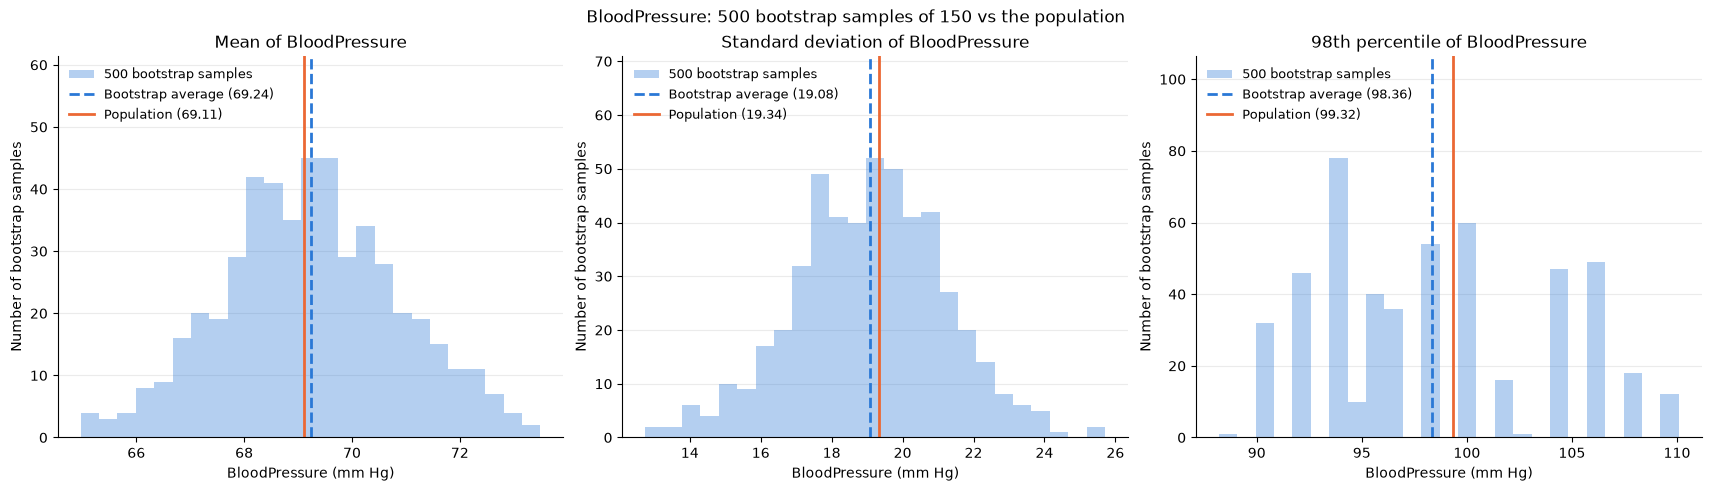

Saved: ..\data\data_results\a2_q2c_bootstrap_samples.csv and ..\data\data_results\a2_q2c_bootstrap_comparison.csv


In [13]:
# BloodPressure bootstrap comparison: sample vs population
N_BOOTSTRAP, BOOT_SIZE, PERCENTILE = 500, 150, 98
STATS = ["mean", "std", f"p{PERCENTILE}"]
STAT_NAMES = {"mean": "Mean", "std": "Standard deviation", f"p{PERCENTILE}": f"{PERCENTILE}th percentile"}
rng = np.random.default_rng(SEED)
blood_pressure = population["BloodPressure"]

boot_rows = []
for sample_id in range(1, N_BOOTSTRAP + 1):
    boot = blood_pressure.sample(n=BOOT_SIZE, replace=True, random_state=rng)
    boot_rows.append({"sample_id": sample_id, "mean": boot.mean(), "std": boot.std(ddof=1),
                      f"p{PERCENTILE}": np.percentile(boot, PERCENTILE)})
bootstrap_stats = pd.DataFrame(boot_rows)
display(bootstrap_stats.head())

population_values = pd.Series({"mean": blood_pressure.mean(), "std": blood_pressure.std(ddof=0),
                               f"p{PERCENTILE}": np.percentile(blood_pressure, PERCENTILE)})
bp_comparison = pd.DataFrame({
    "population": population_values,
    "bootstrap_average": bootstrap_stats[STATS].mean(),
    "bootstrap_spread_sd": bootstrap_stats[STATS].std(ddof=1),
    "bootstrap_2.5%": bootstrap_stats[STATS].quantile(0.025),
    "bootstrap_97.5%": bootstrap_stats[STATS].quantile(0.975),
})
bp_comparison["difference"] = bp_comparison["bootstrap_average"] - bp_comparison["population"]
bp_comparison["pct_difference"] = bp_comparison["difference"] / bp_comparison["population"] * 100
bp_comparison["se_of_average"] = bp_comparison["bootstrap_spread_sd"] / np.sqrt(N_BOOTSTRAP)
display(bp_comparison.round(3))

print(f"Theoretical standard error, population sd / sqrt({BOOT_SIZE}):",
      round(population_values["std"] / np.sqrt(BOOT_SIZE), 3))
print("BloodPressure zeros in the population:", int(blood_pressure.eq(0).sum()))
print("Bootstrap samples with a 98th percentile below the population value:",
      int((bootstrap_stats[f"p{PERCENTILE}"] < population_values[f"p{PERCENTILE}"]).sum()), "of", N_BOOTSTRAP)

fig_2c, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
for ax, stat in zip(axes, STATS):
    ax.hist(bootstrap_stats[stat], bins=25, color=SAMPLE_COLOR, alpha=0.35,
            label=f"{N_BOOTSTRAP} bootstrap samples")
    ax.axvline(bp_comparison.loc[stat, "bootstrap_average"], color=SAMPLE_COLOR, linewidth=2,
               linestyle="--", label=f"Bootstrap average ({bp_comparison.loc[stat, 'bootstrap_average']:.2f})")
    ax.axvline(bp_comparison.loc[stat, "population"], color=POPULATION_COLOR, linewidth=2,
               label=f"Population ({bp_comparison.loc[stat, 'population']:.2f})")
    ax.set(title=f"{STAT_NAMES[stat]} of BloodPressure", xlabel="BloodPressure (mm Hg)",
           ylabel="Number of bootstrap samples")
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
fig_2c.suptitle(f"BloodPressure: {N_BOOTSTRAP} bootstrap samples of {BOOT_SIZE} vs the population",
                fontsize=12)

fig_2c_path = Path("a2_q2c_bootstrap_bloodpressure.png")
fig_2c.savefig(fig_2c_path, dpi=150, bbox_inches="tight")
plt.show()

bootstrap_samples_path = RESULTS_DIR / "a2_q2c_bootstrap_samples.csv"
bootstrap_comparison_path = RESULTS_DIR / "a2_q2c_bootstrap_comparison.csv"
bootstrap_stats.to_csv(bootstrap_samples_path, index=False)
bp_comparison.rename_axis("statistic").to_csv(bootstrap_comparison_path)
print("Saved:", bootstrap_samples_path, "and", bootstrap_comparison_path)

### 2c written response

I drew 500 samples of 150 BloodPressure values with `replace=True` and recorded the mean, standard deviation, and 98th percentile of each one. The `se_of_average` column (spread ÷ √500) shows how much each average could move just from randomness, which helps tell real bias apart from noise.

The mean was the most accurate. The average of the 500 sample means is 69.24 vs the population's 69.11, a difference of 0.13 (0.19%). That's less than two standard errors, so it's just noise. The sample means themselves ranged from 66.14 to 72.50 (middle 95%), and their spread of 1.64 is close to the theoretical standard error of 19.34/√150 = 1.58, which is the Central Limit Theorem showing up.

The standard deviation came out a little low, 19.08 vs 19.34 (−1.36%), even with `ddof=1`. Using n−1 makes the variance unbiased, but taking the square root still makes the SD slightly low on average. The individual SDs also varied a lot (14.74 to 23.22) because the population has 35 zero blood pressures, and the number of zeros that end up in a sample changes its SD a lot.

The 98th percentile was the least reliable. Its average is 98.36 vs 99.32, about 0.96 lower. That's around four standard errors (0.239), so it's a real downward bias and not noise, and 297 of the 500 samples came in below the population value. With 150 values the 98th percentile depends on only the top 3 or so, so it varies a lot more (a spread of 5.34 vs 1.64 for the mean). The histogram is lumpy because blood pressure is recorded in whole numbers.

Overall, the bootstrap averages all came within about 1.4% of the population values. Statistics that use every value, like the mean, are much more stable than ones that depend on the extremes, like a high percentile, which also tend to come out low.

## Output check

In [14]:
expected_files = {
    "Q1 clean data": clean_path,
    "Q1 brand summary": brand_summary_path,
    "Q2a/b sample vs population": sample_vs_population_path,
    "Q2c bootstrap samples": bootstrap_samples_path,
    "Q2c bootstrap comparison": bootstrap_comparison_path,
    "Q2a chart": fig_2a_path,
    "Q2b chart": fig_2b_path,
    "Q2c chart": fig_2c_path,
}
for label, path in expected_files.items():
    print(f"{label}: {path} exists: {path.is_file()}")

assert all(path.is_file() for path in expected_files.values())
assert clean.notna().all().all() and "New_Price" not in clean.columns
assert {"Fuel_Type_Diesel", "Fuel_Type_Petrol", "Transmission_Automatic", "Transmission_Manual", "Car_Age"} <= set(clean.columns)
assert len(sample_25) == 25 and len(bootstrap_stats) == 500
assert pd.read_csv(CARS_PATH).shape == (5847, 14) and pd.read_csv(DIABETES_PATH).shape == (768, 9)
print("All checks passed.")

Q1 clean data: ..\data\data_clean\a2_used_cars_clean.csv exists: True
Q1 brand summary: ..\data\data_results\a2_q1_brand_summary.csv exists: True
Q2a/b sample vs population: ..\data\data_results\a2_q2_sample_vs_population.csv exists: True
Q2c bootstrap samples: ..\data\data_results\a2_q2c_bootstrap_samples.csv exists: True
Q2c bootstrap comparison: ..\data\data_results\a2_q2c_bootstrap_comparison.csv exists: True
Q2a chart: a2_q2a_glucose.png exists: True
Q2b chart: a2_q2b_bmi_p98.png exists: True
Q2c chart: a2_q2c_bootstrap_bloodpressure.png exists: True
All checks passed.
